#EEG FFT etc

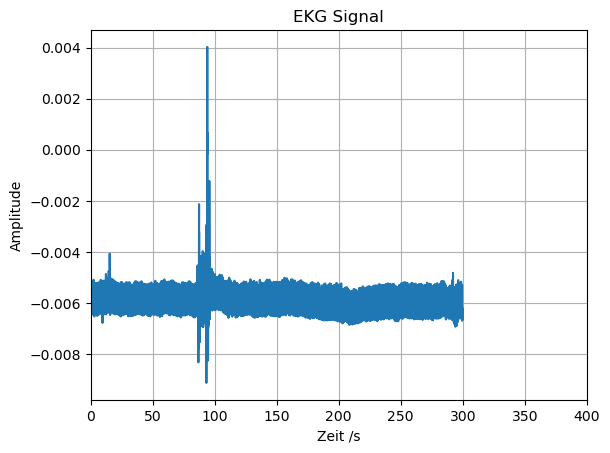

In [ ]:
#-------------------------------------------------------
#-- Titel       : Auswertungsdatei EKG und EEG-Signale
#-------------------------------------------------------
#-- Projekt     : Vorabklärung Signaluntersuchung
#-- Filename    : plot_results.ipynb
#-- Autor       : Stefan Foltrauer
#-- Letze Änderungen : 18.10.2026
#-------------------------------------------------------
#-- Beschreibung: 
#-- EKG und EEG Signale werden untersucht
#-- Es wurde am Ende noch ein FFT-Plot hinzugefügt, um die Frequenzanteile zwichen Artefaktbelasteten und saubere Signal (generischen) zu vergleichen.
#-------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import periodogram, detrend, welch
from scipy.io import loadmat

# Sampling frequency
fs = 1000
# data = np.loadtxt(r"EKG mit Artefakten\S02.txt")
# data = np.loadtxt(r"EKG mit Artefakten\S03.txt")
# data = np.loadtxt(r"EKG mit Artefakten\S07.txt")
# data = np.loadtxt(r"EKG mit Artefakten\S09.txt")
# data = np.loadtxt(r"EKG mit Artefakten\S11.txt")
data = np.loadtxt(r"EKG mit Artefakten\S12.txt")

eKg = data[:, 0]

#eKg = np.loadtxt(r"EKG Daten mit hohen Frequenzanteilen\ECG_high_intensity_exercise\ECG_high_intensity_exercise\ecg_segments\ecg_raw_sub1_seg2.csv",delimiter=",",usecols=0) 
#eKg = np.loadtxt(r"EKG Daten mit hohen Frequenzanteilen\ECG_high_intensity_exercise\ECG_high_intensity_exercise\ecg_segments\ecg_sub1_seg2.csv",delimiter=",",usecols=0)


time = np.arange(len(eKg)) / fs

# Plot the Signal
plt.plot(time, eKg)
plt.xlabel("Zeit /s")
plt.ylabel("Amplitude")
plt.title("EKG Signal")
plt.xlim(0, 400)
plt.grid()
plt.show()

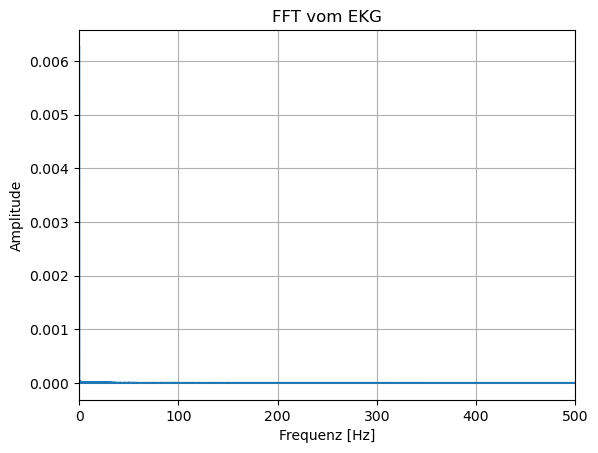

0.000 Hz   Amplitude: 0.006263
0.003 Hz   Amplitude: 0.000176
0.013 Hz   Amplitude: 0.000117
0.023 Hz   Amplitude: 0.000069
0.037 Hz   Amplitude: 0.000062
0.027 Hz   Amplitude: 0.000062
0.010 Hz   Amplitude: 0.000059
0.020 Hz   Amplitude: 0.000051
0.030 Hz   Amplitude: 0.000050
0.017 Hz   Amplitude: 0.000047
0.007 Hz   Amplitude: 0.000043
0.063 Hz   Amplitude: 0.000042
0.050 Hz   Amplitude: 0.000036
0.047 Hz   Amplitude: 0.000036
0.040 Hz   Amplitude: 0.000035
0.033 Hz   Amplitude: 0.000035
1.083 Hz   Amplitude: 0.000034
0.057 Hz   Amplitude: 0.000030
0.060 Hz   Amplitude: 0.000029
0.610 Hz   Amplitude: 0.000029


In [5]:
# FFT
fft_values = np.fft.rfft(eKg)
frequencies = np.fft.rfftfreq(len(eKg), d=1/fs)

magnitude = np.abs(fft_values) / len(eKg) # für das normierte Amplitudenspektrum
magnitude[1:-1] = 2 * magnitude[1:-1]    # Korrektur für einseitiges Spektrum

plt.plot(frequencies, magnitude)
plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("FFT vom EKG")
plt.xlim(0, 500)
plt.grid()
plt.show()

# gibt die zehn größten Frequenzen und deren Amplituden aus
magnitude_copy = magnitude.tolist()
for n in range(20):
    max_value = max(magnitude_copy)
    max_index = magnitude_copy.index(max_value)

    print(f"{frequencies[max_index]:.3f} Hz   Amplitude: {max_value:.6f}")

    magnitude_copy[max_index] = 0

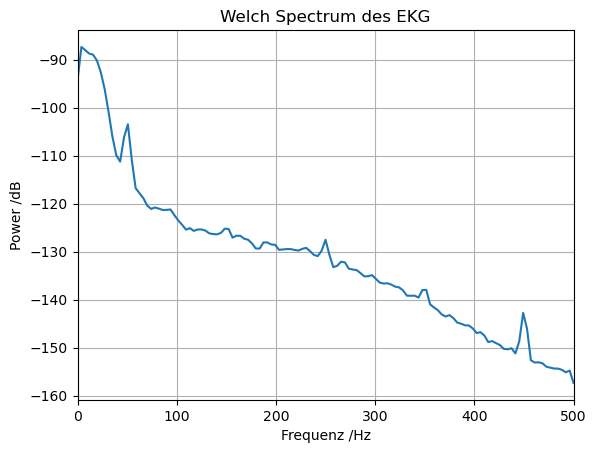

In [55]:
# Welch spectrum
frequencies_welch, power = welch(eKg, fs=fs)

power_dB = 10 * np.log10(power)

plt.plot(frequencies_welch, power_dB)
plt.xlabel("Frequenz /Hz")
plt.ylabel("Power /dB")
plt.title("Welch Spectrum des EKG")
plt.xlim(0, 500)
plt.grid()
plt.show()

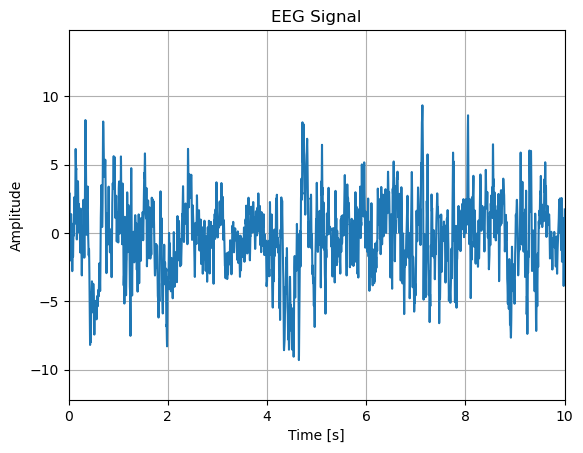

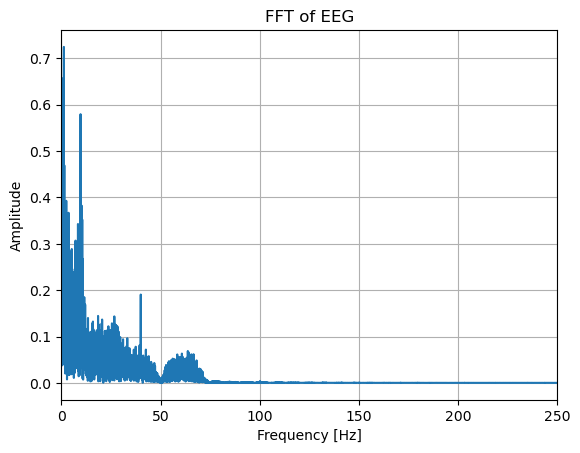

In [6]:
# EEG Vergleich
# Load EEG file
data = loadmat(
    r"EEG Gamma Wellen\sub-1_task-MultisensoryGammaEntrainment_eeg.set",
    squeeze_me=True,
    struct_as_record=False
)

EEG = data["EEG"]

# Sampling frequency
fs = EEG.srate

# EEG data
eeg = EEG.data

# Select channel 1 and first epoch
signal = eeg[0, :, 0]

# Time axis
time = np.arange(len(signal)) / fs

# Plot signal
plt.plot(time, signal)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("EEG Signal")
plt.xlim(0, 10)
plt.grid()
plt.show()

# FFT
fft_values = np.fft.rfft(signal)
frequencies = np.fft.rfftfreq(len(signal), d=1/fs)

magnitude = np.abs(fft_values) / len(signal)
magnitude[1:-1] = 2 * magnitude[1:-1]

plt.plot(frequencies, magnitude)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("FFT of EEG")
plt.xlim(0, 250)
plt.grid()
plt.show()

#Vergleich für die Dämpfung

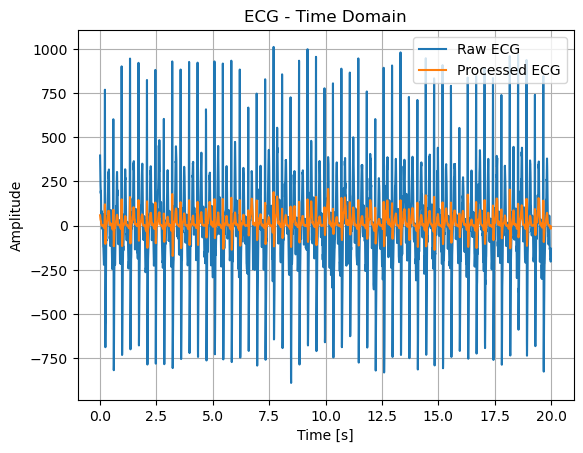

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

fs = 250 #wurde heruntergesamplet

# Load raw ECG
eKg_raw = np.loadtxt(r"EKG Daten mit hohen Frequenzanteilen\ECG_high_intensity_exercise\ECG_high_intensity_exercise\ecg_segments\ecg_raw_sub1_seg2.csv",delimiter=",",usecols=0)

# Load processed ECG
eKg_processed = np.loadtxt(r"EKG Daten mit hohen Frequenzanteilen\ECG_high_intensity_exercise\ECG_high_intensity_exercise\ecg_segments\ecg_sub1_seg2.csv",delimiter=",",usecols=0)
#Zeitbereich für die Darstellung der Signale
time = np.arange(len(eKg_raw)) / fs

plt.plot(time, eKg_raw, label="Raw ECG")
plt.plot(time, eKg_processed, label="Processed ECG")

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("ECG - Time Domain")
plt.legend()
plt.grid()
plt.show()


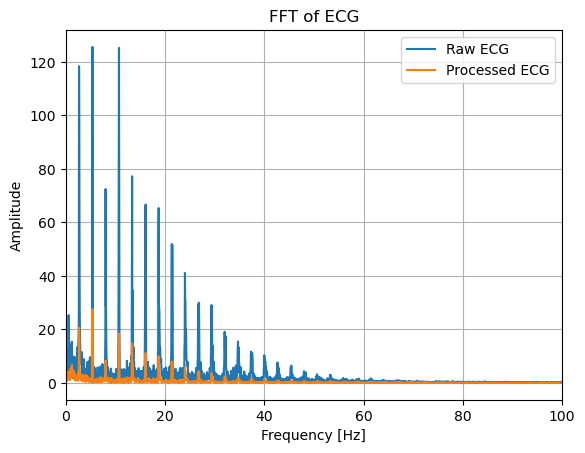

In [6]:

# 2. FFT

fft_raw = np.fft.rfft(eKg_raw)
fft_processed = np.fft.rfft(eKg_processed)

frequencies = np.fft.rfftfreq(len(eKg_raw), d=1/fs)

magnitude_raw = np.abs(fft_raw) / len(eKg_raw)
magnitude_processed = np.abs(fft_processed) / len(eKg_processed)

magnitude_raw[1:-1] = 2 * magnitude_raw[1:-1]
magnitude_processed[1:-1] = 2 * magnitude_processed[1:-1]

plt.plot(frequencies, magnitude_raw, label="Raw ECG")
plt.plot(frequencies, magnitude_processed, label="Processed ECG")

plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("FFT of ECG")
plt.xlim(0, 100)
plt.legend()
plt.grid()
plt.show()


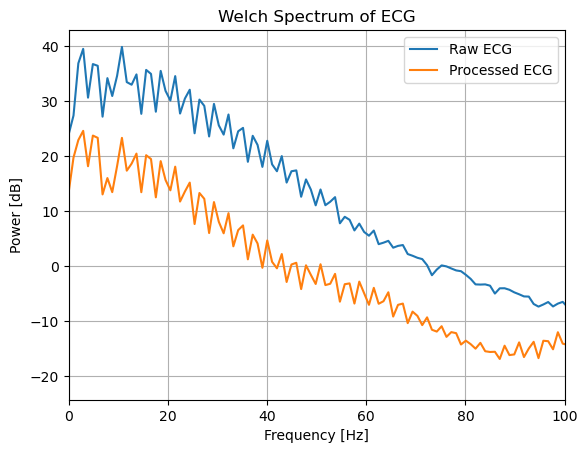

In [7]:
# 3. Welch spectrum

frequencies_welch, power_raw = welch(eKg_raw, fs=fs)
frequencies_welch, power_processed = welch(eKg_processed, fs=fs)

power_raw_dB = 10 * np.log10(power_raw)
power_processed_dB = 10 * np.log10(power_processed)

plt.plot(frequencies_welch, power_raw_dB, label="Raw ECG")
plt.plot(frequencies_welch, power_processed_dB, label="Processed ECG")

plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Welch Spectrum of ECG")
plt.xlim(0, 100)
plt.legend()
plt.grid()
plt.show()

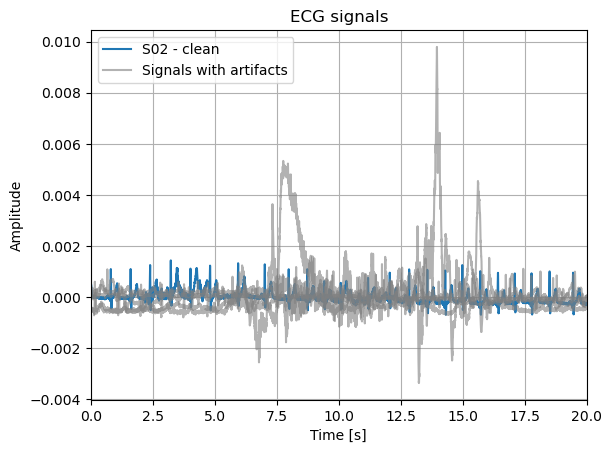

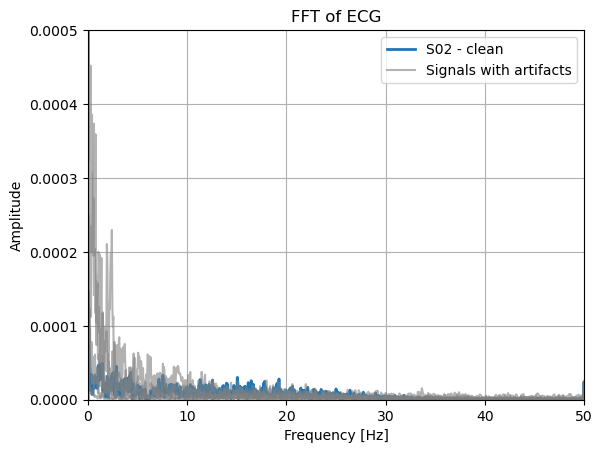

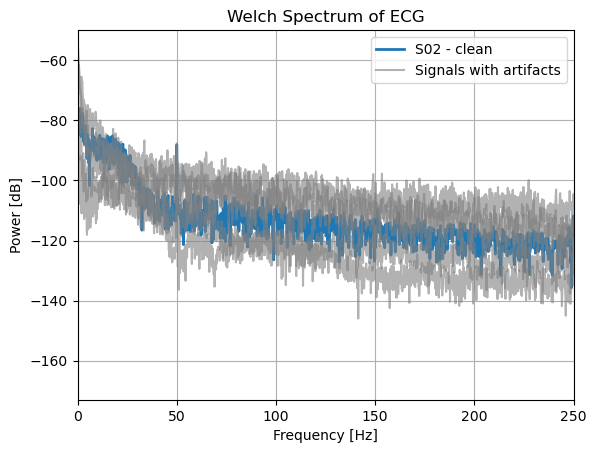

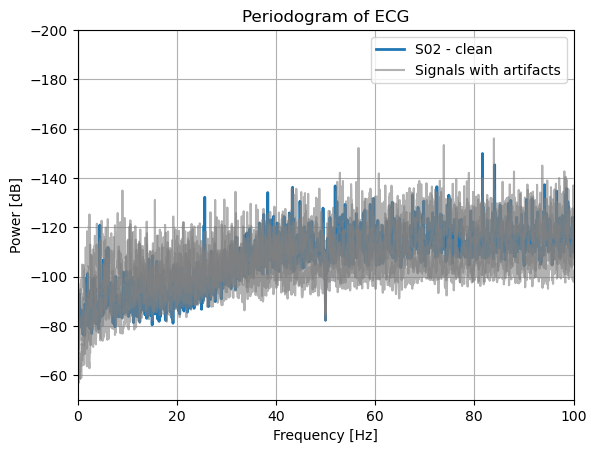

In [ ]:
#Vergleich von EKG Signalen mit Artefakten und einem sauberen EKG Signal
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Sampling frequency
fs = 1000

# Clean ECG
data_S02 = np.loadtxt(r"EKG mit Artefakten\S02.txt")
eKg_S02 = data_S02[:, 0]

# ECG with artifacts
data_S03 = np.loadtxt(r"EKG mit Artefakten\S03.txt")
data_S07 = np.loadtxt(r"EKG mit Artefakten\S07.txt")
data_S09 = np.loadtxt(r"EKG mit Artefakten\S09.txt")
data_S11 = np.loadtxt(r"EKG mit Artefakten\S11.txt")
data_S12 = np.loadtxt(r"EKG mit Artefakten\S12.txt")

eKg_S03 = data_S03[:, 0]
eKg_S07 = data_S07[:, 0]
eKg_S09 = data_S09[:, 0]
eKg_S11 = data_S11[:, 0]
eKg_S12 = data_S12[:, 0]

samples_20s = 20 * fs

eKg_S02 = eKg_S02[:samples_20s]
eKg_S03 = eKg_S03[:samples_20s]
eKg_S07 = eKg_S07[:samples_20s]
eKg_S09 = eKg_S09[:samples_20s]
eKg_S11 = eKg_S11[210*fs : 230*fs]
eKg_S12 = eKg_S12[80*fs : 100*fs]


# Remove DC component
eKg_S02 = eKg_S02 - np.mean(eKg_S02)
eKg_S03 = eKg_S03 - np.mean(eKg_S03)
eKg_S07 = eKg_S07 - np.mean(eKg_S07)
eKg_S09 = eKg_S09 - np.mean(eKg_S09)
eKg_S11 = eKg_S11 - np.mean(eKg_S11)
eKg_S12 = eKg_S12 - np.mean(eKg_S12)


# --------------------------------------------------
# Time domain
# --------------------------------------------------

time = np.arange(len(eKg_S02)) / fs

plt.plot(time, eKg_S02, label="S02 - clean")

plt.plot(time, eKg_S03, color="gray", alpha=0.6, label="Signals with artifacts")
plt.plot(time, eKg_S07, color="gray", alpha=0.6)
plt.plot(time, eKg_S09, color="gray", alpha=0.6)
plt.plot(time, eKg_S11, color="gray", alpha=0.6)
plt.plot(time, eKg_S12, color="gray", alpha=0.6)

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("ECG signals")
plt.xlim(0, 20)
plt.legend()
plt.grid()
plt.show()


# --------------------------------------------------
# FFT
# --------------------------------------------------

signals = [eKg_S03, eKg_S07, eKg_S09, eKg_S11, eKg_S12]

fft_clean = np.fft.rfft(eKg_S02)
frequencies = np.fft.rfftfreq(len(eKg_S02), d=1/fs)

magnitude_clean = np.abs(fft_clean) / len(eKg_S02)
magnitude_clean[1:-1] = 2 * magnitude_clean[1:-1]

plt.plot(frequencies, magnitude_clean,
         label="S02 - clean", linewidth=2)

first = True

for signal in signals:

    fft_values = np.fft.rfft(signal)

    magnitude = np.abs(fft_values) / len(signal)
    magnitude[1:-1] = 2 * magnitude[1:-1]

    if first:
        plt.plot(frequencies, magnitude,
                 color="gray", alpha=0.6,
                 label="Signals with artifacts")
        first = False
    else:
        plt.plot(frequencies, magnitude,
                 color="gray", alpha=0.6)

plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("FFT of ECG")
plt.xlim(0, 50)
plt.ylim(0, 0.0005)
plt.legend()
plt.grid()
plt.show()


# --------------------------------------------------
# Welch
# --------------------------------------------------

frequencies_welch, power_clean = welch(
    eKg_S02,
    fs=fs,
    nperseg=8192
)

power_clean_dB = 10 * np.log10(power_clean)

plt.plot(
    frequencies_welch,
    power_clean_dB,
    label="S02 - clean",
    linewidth=2
)

first = True

for signal in signals:

    frequencies_welch, power = welch(
        signal,
        fs=fs,
        nperseg=8192
    )

    power_dB = 10 * np.log10(power)

    if first:
        plt.plot(
            frequencies_welch,
            power_dB,
            color="gray",
            alpha=0.6,
            label="Signals with artifacts"
        )
        first = False
    else:
        plt.plot(
            frequencies_welch,
            power_dB,
            color="gray",
            alpha=0.6
        )

plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Welch Spectrum of ECG")
plt.xlim(0, 250)
plt.legend()
plt.grid()
plt.show()
# --------------------------------------------------
# Periodogram
# --------------------------------------------------

frequencies_periodogram, power_clean_periodogram = periodogram(
    eKg_S02,
    fs=fs
)

power_clean_periodogram_dB = 10 * np.log10(power_clean_periodogram)

plt.plot(
    frequencies_periodogram,
    power_clean_periodogram_dB,
    label="S02 - clean",
    linewidth=2
)

first = True

for signal in signals:

    frequencies_periodogram, power_periodogram = periodogram(
        signal,
        fs=fs
    )

    power_periodogram_dB = 10 * np.log10(power_periodogram)

    if first:
        plt.plot(
            frequencies_periodogram,
            power_periodogram_dB,
            color="gray",
            alpha=0.6,
            label="Signals with artifacts"
        )
        first = False
    else:
        plt.plot(
            frequencies_periodogram,
            power_periodogram_dB,
            color="gray",
            alpha=0.6
        )

plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Periodogram of ECG")
plt.xlim(0, 100)
plt.ylim(-50, -200)
plt.legend()
plt.grid()
plt.show()

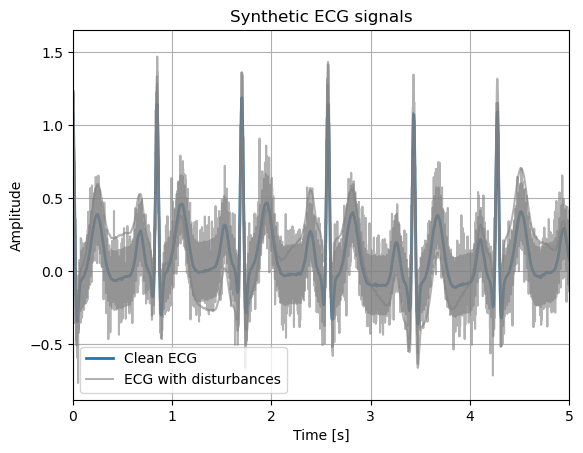

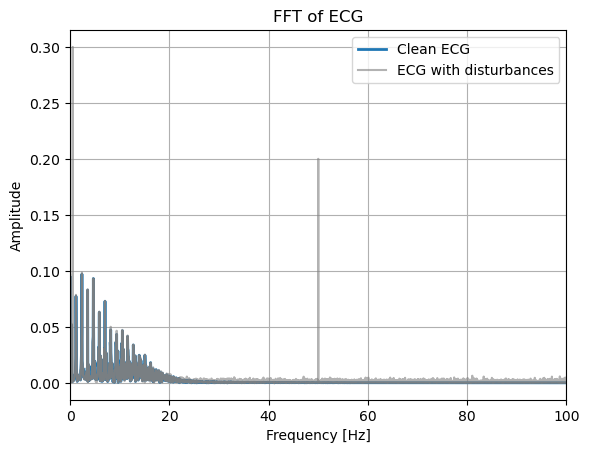

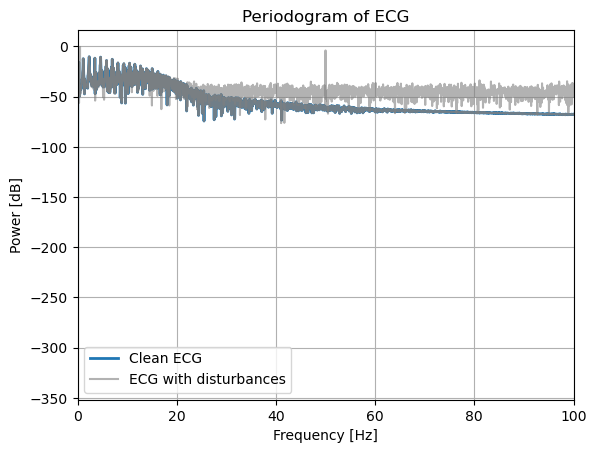

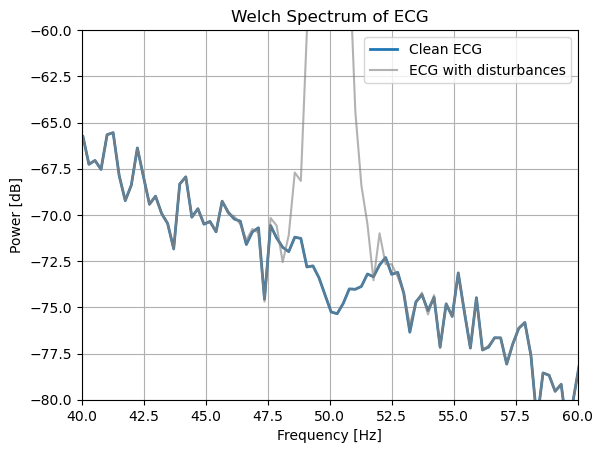

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from scipy.signal import periodogram, welch

# --------------------------------------------------
# Parameters
# --------------------------------------------------

fs = 1000
duration = 20

# --------------------------------------------------
# Generate clean ECG
# --------------------------------------------------

eKg_clean = nk.ecg_simulate(
    duration=duration,
    sampling_rate=fs,
    heart_rate=70
)

time = np.arange(len(eKg_clean)) / fs


# --------------------------------------------------
# Create signals with different disturbances
# --------------------------------------------------

# 50 Hz mains interference
noise_50Hz = 0.2 * np.sin(2 * np.pi * 50 * time)

# Slow baseline wander
noise_baseline = 0.3 * np.sin(2 * np.pi * 0.5 * time)

# Random broadband noise
noise_random = 0.15 * np.random.randn(len(eKg_clean))

# Combined disturbances
eKg_50Hz = eKg_clean + noise_50Hz
eKg_baseline = eKg_clean + noise_baseline
eKg_random = eKg_clean + noise_random

signals = [
    eKg_50Hz,
    eKg_baseline,
    eKg_random
]


# --------------------------------------------------
# Time domain
# --------------------------------------------------

plt.plot(time, eKg_clean,
         label="Clean ECG",
         linewidth=2)

first = True

for signal in signals:

    if first:
        plt.plot(time, signal,
                 color="gray",
                 alpha=0.6,
                 label="ECG with disturbances")
        first = False
    else:
        plt.plot(time, signal,
                 color="gray",
                 alpha=0.6)

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Synthetic ECG signals")
plt.xlim(0, 5)
plt.legend()
plt.grid()
plt.show()


# --------------------------------------------------
# FFT
# --------------------------------------------------

fft_clean = np.fft.rfft(eKg_clean)

frequencies = np.fft.rfftfreq(
    len(eKg_clean),
    d=1/fs
)

magnitude_clean = (
    np.abs(fft_clean) / len(eKg_clean)
)

magnitude_clean[1:-1] = (
    2 * magnitude_clean[1:-1]
)

plt.plot(
    frequencies,
    magnitude_clean,
    label="Clean ECG",
    linewidth=2
)

first = True

for signal in signals:

    fft_values = np.fft.rfft(signal)

    magnitude = (
        np.abs(fft_values) / len(signal)
    )

    magnitude[1:-1] = (
        2 * magnitude[1:-1]
    )

    if first:
        plt.plot(
            frequencies,
            magnitude,
            color="gray",
            alpha=0.6,
            label="ECG with disturbances"
        )
        first = False

    else:
        plt.plot(
            frequencies,
            magnitude,
            color="gray",
            alpha=0.6
        )

plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("FFT of ECG")
plt.xlim(0, 100)
plt.legend()
plt.grid()
plt.show()


# --------------------------------------------------
# Periodogram
# --------------------------------------------------

frequencies_periodogram, power_clean = periodogram(
    eKg_clean,
    fs=fs
)

power_clean_dB = 10 * np.log10(power_clean)

plt.plot(
    frequencies_periodogram,
    power_clean_dB,
    label="Clean ECG",
    linewidth=2
)

first = True

for signal in signals:

    frequencies_periodogram, power = periodogram(
        signal,
        fs=fs
    )

    power_dB = 10 * np.log10(power)

    if first:
        plt.plot(
            frequencies_periodogram,
            power_dB,
            color="gray",
            alpha=0.6,
            label="ECG with disturbances"
        )
        first = False

    else:
        plt.plot(
            frequencies_periodogram,
            power_dB,
            color="gray",
            alpha=0.6
        )

plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Periodogram of ECG")
plt.xlim(0, 100)
plt.legend()
plt.grid()
plt.show()


# --------------------------------------------------
# Welch
# --------------------------------------------------

frequencies_welch, power_clean = welch(
    eKg_clean,
    fs=fs,
    nperseg=4096
)

power_clean_dB = 10 * np.log10(power_clean)

plt.plot(
    frequencies_welch,
    power_clean_dB,
    label="Clean ECG",
    linewidth=2
)

first = True

for signal in signals:

    frequencies_welch, power = welch(
        signal,
        fs=fs,
        nperseg=4096
    )

    power_dB = 10 * np.log10(power)

    if first:
        plt.plot(
            frequencies_welch,
            power_dB,
            color="gray",
            alpha=0.6,
            label="ECG with disturbances"
        )
        first = False

    else:
        plt.plot(
            frequencies_welch,
            power_dB,
            color="gray",
            alpha=0.6
        )

plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Welch Spectrum of ECG")
plt.xlim(40, 60)
plt.ylim(-80, -60)
plt.legend()
plt.grid()
plt.show()

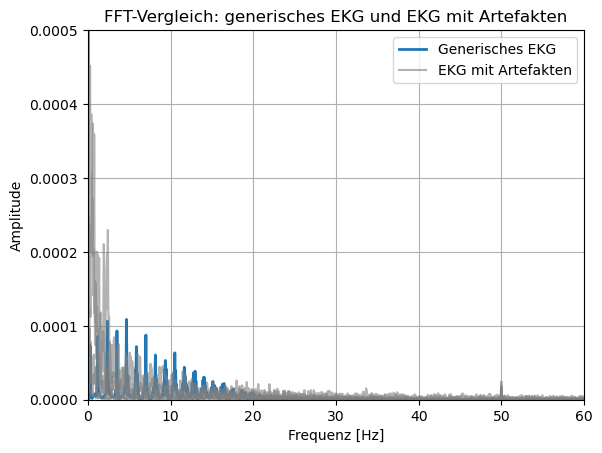

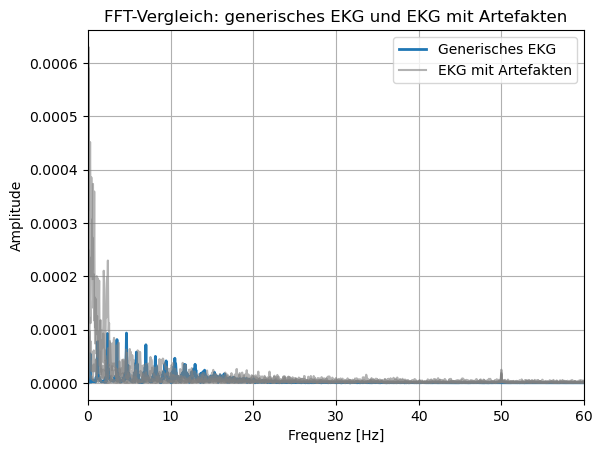

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk

fs = 1000
duration = 20
samples_20s = duration * fs

# --------------------------------------------------
# Generisches EKG
# --------------------------------------------------

eKg_generic = nk.ecg_simulate(
    duration=duration,
    sampling_rate=fs,
    heart_rate=70
)

# DC entfernen
eKg_generic = eKg_generic - np.mean(eKg_generic)

# Generisches EKG in eine realistische Größenordnung bringen
# ca. 1 mV Spitzenbereich
eKg_generic = eKg_generic * 0.001


# --------------------------------------------------
# EKG mit Artefakten laden
# --------------------------------------------------

data_S03 = np.loadtxt(r"EKG mit Artefakten\S03.txt")
data_S07 = np.loadtxt(r"EKG mit Artefakten\S07.txt")
data_S09 = np.loadtxt(r"EKG mit Artefakten\S09.txt")
data_S11 = np.loadtxt(r"EKG mit Artefakten\S11.txt")
data_S12 = np.loadtxt(r"EKG mit Artefakten\S12.txt")

eKg_S03 = data_S03[:samples_20s, 0]
eKg_S07 = data_S07[:samples_20s, 0]
eKg_S09 = data_S09[:samples_20s, 0]
eKg_S11 = data_S11[210*fs:230*fs, 0]
eKg_S12 = data_S12[80*fs:100*fs, 0]

# DC entfernen
eKg_S03 = eKg_S03 - np.mean(eKg_S03)
eKg_S07 = eKg_S07 - np.mean(eKg_S07)
eKg_S09 = eKg_S09 - np.mean(eKg_S09)
eKg_S11 = eKg_S11 - np.mean(eKg_S11)
eKg_S12 = eKg_S12 - np.mean(eKg_S12)


# --------------------------------------------------
# FFT generisches EKG
# --------------------------------------------------

fft_generic = np.fft.rfft(eKg_generic)

frequencies = np.fft.rfftfreq(
    len(eKg_generic),
    d=1/fs
)

magnitude_generic = (
    np.abs(fft_generic) / len(eKg_generic)
)

magnitude_generic[1:-1] = (
    2 * magnitude_generic[1:-1]
)

plt.plot(
    frequencies,
    magnitude_generic,
    label="Generisches EKG",
    linewidth=2
)


# --------------------------------------------------
# FFT der artefaktbelasteten EKGs
# --------------------------------------------------

signals = [
    eKg_S03,
    eKg_S07,
    eKg_S09,
    eKg_S11,
    eKg_S12
]

first = True

for signal in signals:

    fft_values = np.fft.rfft(signal)

    magnitude = (
        np.abs(fft_values) / len(signal)
    )

    magnitude[1:-1] = (
        2 * magnitude[1:-1]
    )

    if first:
        plt.plot(
            frequencies,
            magnitude,
            color="gray",
            alpha=0.6,
            label="EKG mit Artefakten"
        )
        first = False
    else:
        plt.plot(
            frequencies,
            magnitude,
            color="gray",
            alpha=0.6
        )


# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("FFT-Vergleich: generisches EKG und EKG mit Artefakten")

plt.xlim(0, 60)

plt.legend()
plt.grid()
plt.show()